ML environment ready
(300, 2)
X shape: (300, 2)
   Annual Spending  Visits per Month
0      9043.482514          2.656554
1     12278.086377          2.110923
2    101804.434476         16.543317
3     40184.913490          8.924207
4     15291.043592          1.000000
Scaled data:
[[-1.26133223 -1.02024336]
 [-1.17257335 -1.11937394]
 [ 1.28406699  1.5027123 ]
 [-0.40679837  0.11846777]
 [-1.08989655 -1.32120704]]


C:\Users\PRADHIKSHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


Cluster labels:
Cluster
0    102
1    101
2     97
Name: count, dtype: int64


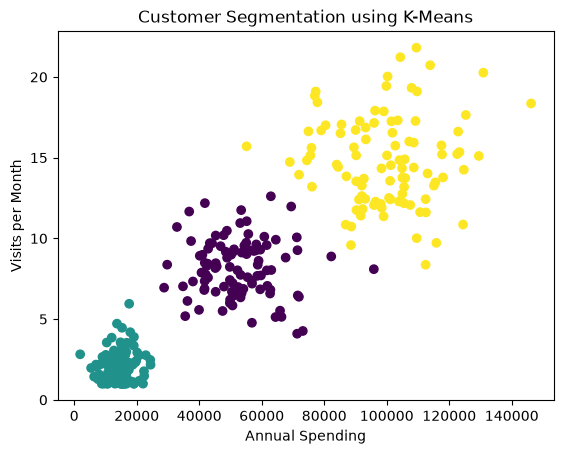

Cluster-wise Average:
         Annual Spending  Visits per Month
Cluster                                   
0           52607.742475          8.123553
1           14453.516824          2.146314
2           99764.078198         14.806825
K = 2
Inertia: 174.85152367572175
Silhouette Score: 0.603361017236387



C:\Users\PRADHIKSHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\Users\PRADHIKSHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


K = 3
Inertia: 66.27596281189282
Silhouette Score: 0.6579602226333712

K = 4
Inertia: 49.237294084706875
Silhouette Score: 0.5979780763289239



C:\Users\PRADHIKSHA\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


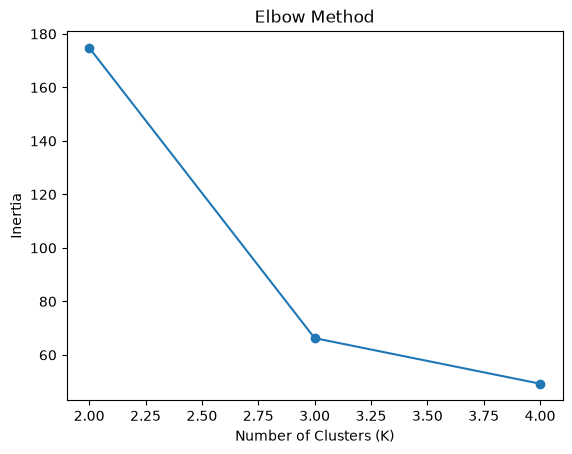

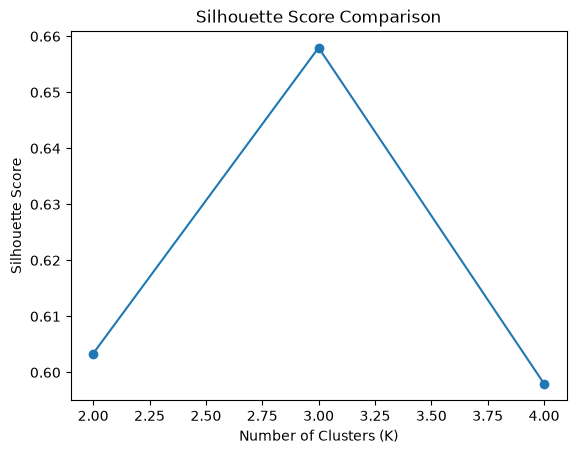

DBSCAN Cluster Labels:
DBSCAN Cluster
-1      1
 0    299
Name: count, dtype: int64


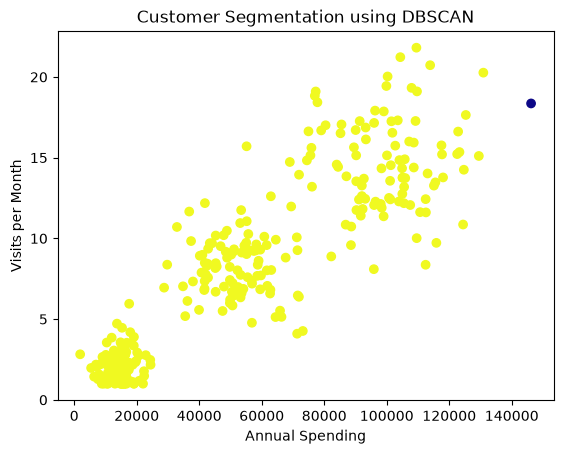

DBSCAN Cluster-wise Average:
                Annual Spending  Visits per Month   Cluster
DBSCAN Cluster                                             
-1                146183.212127         18.358725  2.000000
 0                 54704.773594          8.238406  0.979933
Number of Noise Points: 1
DBSCAN Silhouette Score cannot be calculated

Customer Segment Descriptions

Cluster 0
Average Annual Spending: 52607.74
Average Visits per Month: 8.12
Description: Medium spending customers

Cluster 1
Average Annual Spending: 14453.52
Average Visits per Month: 2.15
Description: Low spending customers

Cluster 2
Average Annual Spending: 99764.08
Average Visits per Month: 14.81
Description: High spending customers

K-Means Comparison
   K     Inertia  Silhouette Score
0  2  174.851524          0.603361
1  3   66.275963          0.657960
2  4   49.237294          0.597978


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("ML environment ready")
from sklearn.datasets import make_blobs
data, labels = make_blobs(
    n_samples=300,
    centers=[[15000, 2], [50000, 8], [100000, 15]],
    cluster_std=[[5000, 1], [10000, 2], [15000, 3]],
    random_state=42
)
df = pd.DataFrame(data, columns=["Annual Spending", "Visits per Month"])
df["Annual Spending"] = df["Annual Spending"].clip(lower=1000)
df["Visits per Month"] = df["Visits per Month"].clip(lower=1)
print(df.shape)
df.head()
X = df[["Annual Spending", "Visits per Month"]]
print("X shape:", X.shape)
print(X.head())
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled data:")
print(X_scaled[:5])
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)
print("Cluster labels:")
print(df["Cluster"].value_counts())
plt.scatter(
    df["Annual Spending"],
    df["Visits per Month"],
    c=df["Cluster"],
    cmap="viridis"
)
plt.xlabel("Annual Spending")
plt.ylabel("Visits per Month")
plt.title("Customer Segmentation using K-Means")
plt.show()
cluster_avg = df.groupby("Cluster").mean()
print("Cluster-wise Average:")
print(cluster_avg)
from sklearn.metrics import silhouette_score
inertia = []
silhouette = []
k_values = [2, 3, 4]
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)

    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X_scaled, model.labels_))

    print("K =", k)
    print("Inertia:", model.inertia_)
    print("Silhouette Score:", silhouette_score(X_scaled, model.labels_))
    print()
plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()
plt.plot(k_values, silhouette, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.show()
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
df["DBSCAN Cluster"] = dbscan.fit_predict(X_scaled)
print("DBSCAN Cluster Labels:")
print(df["DBSCAN Cluster"].value_counts().sort_index())
plt.scatter(
    df["Annual Spending"],
    df["Visits per Month"],
    c=df["DBSCAN Cluster"],
    cmap="plasma"
)
plt.xlabel("Annual Spending")
plt.ylabel("Visits per Month")
plt.title("Customer Segmentation using DBSCAN")
plt.show()
dbscan_avg = df.groupby("DBSCAN Cluster").mean()
print("DBSCAN Cluster-wise Average:")
print(dbscan_avg)
noise = df[df["DBSCAN Cluster"] == -1]
print("Number of Noise Points:", len(noise))
db_labels = df["DBSCAN Cluster"].values
non_noise = db_labels != -1
if len(set(db_labels[non_noise])) > 1:
    db_silhouette = silhouette_score(
        X_scaled[non_noise],
        db_labels[non_noise]
    )
    print("DBSCAN Silhouette Score:", db_silhouette)
else:
    print("DBSCAN Silhouette Score cannot be calculated")
print("\nCustomer Segment Descriptions")
for cluster in sorted(df["Cluster"].unique()):
    group = df[df["Cluster"] == cluster]

    avg_spending = group["Annual Spending"].mean()
    avg_visits = group["Visits per Month"].mean()

    print("\nCluster", cluster)
    print("Average Annual Spending:", round(avg_spending, 2))
    print("Average Visits per Month:", round(avg_visits, 2))

    if avg_spending > 70000:
        print("Description: High spending customers")
    elif avg_spending > 30000:
        print("Description: Medium spending customers")
    else:
        print("Description: Low spending customers")
comparison = pd.DataFrame({
    "K": k_values,
    "Inertia": inertia,
    "Silhouette Score": silhouette
})
print("\nK-Means Comparison")
print(comparison)